# Who churns, and what does it cost? Data audit and SQL findings

**Question.** A telco loses a quarter of its customers in the observed quarter. Where is the loss concentrated, which columns can be trusted, and what should a retention team look at first?

**Data.** IBM Telco customer churn sample dataset: 7,043 customers of one California telco, one observed quarter, 50 columns. It is **cross-sectional**: there is no month-by-month history, so every churn probability in this project means "churns during the observed quarter".

This notebook covers the audit and the SQL analysis. The modeling and decision work is in `02_model_and_decisions.ipynb`.

In [1]:
import json
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
logging.disable(logging.INFO)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def usd(value, decimals=0):
    """Dollar amount with the sign escaped so Markdown does not read paired $ as math."""
    return f"\\${value:,.{decimals}f}"


from src.utils import load_config

config = load_config("configs/project.yaml")

from src.analytics import query_files, run_sql_analysis
from src.data_ingestion import TelcoDataLoader

loader = TelcoDataLoader(config)
raw = loader.load_raw()
df = loader.run()
print(f"{len(df):,} customers, {raw.shape[1]} raw columns, churn rate {df.churn.mean():.1%}")
df[["customer_id", "contract", "internet_type", "tenure_months", "monthly_charge", "customer_status", "churn"]].head()

7,043 customers, 50 raw columns, churn rate 26.5%


,customer_id,contract,internet_type,tenure_months,monthly_charge,customer_status,churn
0,8779-QRDMV,Month-to-Month,DSL,1,39.65,Churned,1
1,7495-OOKFY,Month-to-Month,Fiber Optic,8,80.65,Churned,1
2,1658-BYGOY,Month-to-Month,Fiber Optic,18,95.45,Churned,1
3,4598-XLKNJ,Month-to-Month,Fiber Optic,25,98.50,Churned,1
4,4846-WHAFZ,Month-to-Month,Fiber Optic,37,76.50,Churned,1


## 1. Data quality: two columns that silently corrupt

`pandas.read_csv` treats the text `None` as missing. In this dataset `None` is a real category (no offer, no internet). A default read turns thousands of customers into NaN, and any model that drops or imputes them is quietly wrong. The loader reads with `keep_default_na=False`.

In [2]:
naive = pd.read_csv(config["paths"]["raw_data"])
pd.DataFrame(
    {
        "default read_csv (NaN)": naive[["Offer", "Internet Type"]].isna().sum(),
        "keep_default_na=False (NaN)": raw[["Offer", "Internet Type"]].isna().sum(),
        'rows with the text "None"': (raw[["Offer", "Internet Type"]] == "None").sum(),
    }
)

,default read_csv (NaN),keep_default_na=False (NaN),"rows with the text ""None"""
Offer,3877,0,3877
Internet Type,1526,0,1526


## 2. Leakage audit: which columns must never reach the model

Several columns are recorded **at or after** the outcome. A model that uses them looks brilliant and is useless for deciding whom to contact beforehand. The evidence:

In [3]:
churned = (raw["Churn Label"] == "Yes").astype(int)

by_score = raw.groupby("Satisfaction Score").agg(customers=("Churn Label", "size"), churn_rate=("Churn Label", lambda s: (s == "Yes").mean()))
display(by_score.style.format({"churn_rate": "{:.0%}"}))

print("corr(Churn Score, churned)            :", round(raw["Churn Score"].corr(churned), 2))
print("Churn Reason filled for churners      :", int(raw.loc[churned == 1, "Churn Reason"].notna().sum()), "of", int(churned.sum()))
print("Churn Reason filled for non-churners  :", int(raw.loc[churned == 0, "Churn Reason"].notna().sum()))

,customers,churn_rate
Satisfaction Score,,
1,922,100%
2,518,100%
3,2665,16%
4,1789,0%
5,1149,0%


corr(Churn Score, churned)            : 0.66
Churn Reason filled for churners      : 1869 of 1869
Churn Reason filled for non-churners  : 0


Satisfaction scores of 1 and 2 churn 100% of the time and scores of 4 and 5 never churn. That is not a predictor, it is a record of the exit survey. `Churn Score` is the output of IBM's own model, and `Churn Reason` exists only for customers who already left.

The audit below keeps the model fixed (logistic regression, 5-fold CV) and only changes which columns are allowed in:

,feature_set,n_features,roc_auc,pr_auc,auc_vs_standard,verdict
0,Strict: no lifetime-cumulative columns,30,0.878,0.730,-0.021,conservative sensitivity check
1,Standard: project default,36,0.899,0.768,0.000,used
2,Standard + cltv,37,0.898,0.767,-0.000,"excluded: adds nothing, not reproducible"
3,Standard + satisfaction_score,37,0.992,0.983,0.094,excluded: recorded around exit
4,Standard + churn_score,37,0.981,0.953,0.082,excluded: another model's output
5,Standard + satisfaction_score + churn_score,38,0.998,0.995,0.099,excluded: leakage


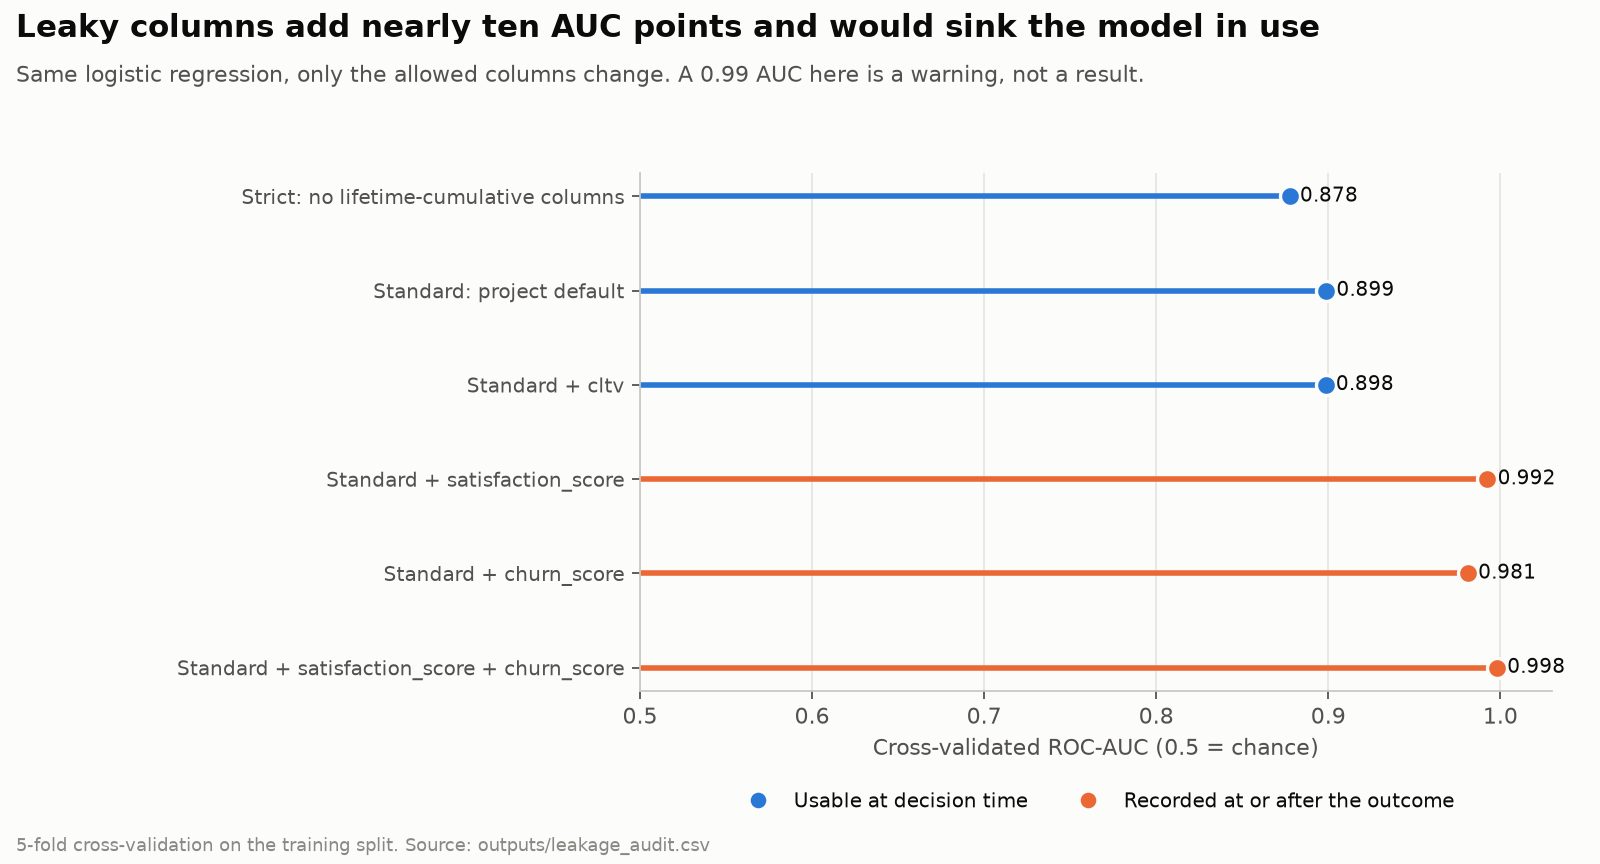

In [4]:
audit = pd.read_csv("outputs/leakage_audit.csv")
display(audit[["feature_set", "n_features", "roc_auc", "pr_auc", "auc_vs_standard", "verdict"]].round(3))
Image("outputs/figures/03_leakage_audit.png")

In [5]:
standard = audit.loc[audit.feature_set.str.startswith("Standard: project"), "roc_auc"].iloc[0]
leaky = audit.loc[audit.feature_set.str.contains("satisfaction_score \\+ churn_score"), "roc_auc"].iloc[0]
strict = audit.loc[audit.feature_set.str.startswith("Strict"), "roc_auc"].iloc[0]
display(Markdown(f"""
- Allowed columns only: **AUC {standard:.3f}**. Adding the two leaky columns: **{leaky:.3f}**, a jump of {100*(leaky-standard):.0f} points that would vanish in production.
- `cltv` adds nothing (it is excluded because it cannot be reproduced, not because it leaks).
- Lifetime-cumulative columns (billing totals, referral count) are measured up to the exit date for churners, so they carry a small look-ahead. The strict set drops them: **AUC {strict:.3f}**. Both numbers are reported; the headline uses the standard set.
"""))


- Allowed columns only: **AUC 0.899**. Adding the two leaky columns: **0.998**, a jump of 10 points that would vanish in production.
- `cltv` adds nothing (it is excluded because it cannot be reproduced, not because it leaks).
- Lifetime-cumulative columns (billing totals, referral count) are measured up to the exit date for churners, so they carry a small look-ahead. The strict set drops them: **AUC 0.878**. Both numbers are reported; the headline uses the standard set.


## 3. SQL analysis: where the loss is

Each query in `sql/` answers one business question with DuckDB against the raw CSV, using CTEs and window functions. The runner executes them all:

In [6]:
sql = run_sql_analysis(config, write_outputs=False)

for path in query_files(config["paths"]["sql"]):
    name = path.stem.split("_", 1)[1]
    question = next(l[12:] for l in path.read_text().splitlines() if l.startswith("-- Question:"))
    display(Markdown(f"**`{path.name}`** &mdash; {question.strip()}"))
    display(sql[name].head(8))

**`01_churn_overview.sql`** &mdash; How big is the churn problem in customers and in recurring revenue?

,customers,churned_customers,churn_rate_pct,monthly_recurring_revenue,monthly_revenue_lost,revenue_lost_pct,avg_charge_churners,avg_charge_stayers
0,7043,1869,26.5,456117.0,139131.0,30.5,74.44,61.27


**`02_churn_by_contract_and_tenure.sql`** &mdash; Where does churn concentrate across contract type and tenure?

,contract,tenure_band,customers,churned,churn_rate_pct,share_of_all_churners_pct
0,Month-to-Month,1: 0-12 months,1913,1024,53.5,54.8
1,Month-to-Month,2: 13-24 months,686,278,40.5,14.9
2,Month-to-Month,3: 25-48 months,715,264,36.9,14.1
3,Month-to-Month,4: 49+ months,296,89,30.1,4.8
4,One Year,4: 49+ months,643,82,12.8,4.4
5,One Year,3: 25-48 months,546,55,10.1,2.9
6,Two Year,4: 49+ months,1300,42,3.2,2.2
7,One Year,2: 13-24 months,215,16,7.4,0.9


**`03_revenue_at_risk_pareto.sql`** &mdash; Which segments account for most of the revenue lost to churn?

,contract,internet_type,customers,churn_rate_pct,monthly_revenue_lost,share_of_loss_pct,cumulative_share_pct
0,Month-to-Month,Fiber Optic,1882,58.8,95594.0,68.7,68.7
1,Month-to-Month,DSL,787,33.3,12190.0,8.8,77.5
2,Month-to-Month,Cable,423,44.2,11065.0,8.0,85.4
3,One Year,Fiber Optic,587,16.7,9976.0,7.2,92.6
4,Two Year,Fiber Optic,566,5.5,3246.0,2.3,94.9
5,One Year,DSL,406,8.9,2232.0,1.6,96.5
6,Month-to-Month,None,518,19.1,1998.0,1.4,98.0
7,One Year,Cable,191,12.0,1720.0,1.2,99.2


... (2 outputs left out)

**`05_price_quintiles_and_payment.sql`** &mdash; Is churn driven by price level, and does payment method matter?

,contract,price_quintile,customers,min_charge,max_charge,churn_rate_pct,churn_pct_mailed_check,churn_pct_bank_withdrawal
0,Month-to-Month,1,722,18.75,36.00,25.5,43.5,34.4
1,Month-to-Month,2,722,36.25,60.25,37.5,62.5,39.4
2,Month-to-Month,3,722,60.35,78.80,49.9,56.5,55.2
3,Month-to-Month,4,722,78.80,90.70,57.6,75.0,61.7
4,Month-to-Month,5,722,90.70,117.45,58.7,75.0,61.2
5,One Year,1,310,18.25,24.10,2.3,3.2,4.2
6,One Year,2,310,24.10,59.30,6.1,13.6,7.1
7,One Year,3,310,59.30,79.45,9.7,28.6,7.5


**`06_offer_confounding.sql`** &mdash; Which retention offers work?

,offer,tenure_band,customers,churn_pct,offer_raw_churn_pct,no_offer_customers,no_offer_churn_pct,gap_vs_no_offer_points
0,Offer A,5: 49+ months,520,6.7,6.7,1138,10.0,-3.3
1,Offer B,4: 25-48 months,243,15.2,12.3,971,20.7,-5.5
2,Offer B,5: 49+ months,581,11.0,12.3,1138,10.0,1.0
3,Offer C,3: 13-24 months,35,22.9,22.9,548,31.4,-8.5
4,Offer C,4: 25-48 months,380,22.9,22.9,971,20.7,2.2
5,Offer D,2: 7-12 months,161,29.2,26.7,385,38.2,-9.0
6,Offer D,3: 13-24 months,441,25.9,26.7,548,31.4,-5.5
7,Offer E,1: 0-6 months,635,57.8,52.9,835,49.9,7.9



### What the queries say

- **26.5% of customers churned, but 30.5% of monthly revenue.** Churners pay \$74.44 a month against \$61.27 for stayers, so the revenue problem is bigger than the headcount problem.
- **Month-to-month customers in their first year are 55% of all churners** (54% of them churn).
- **Month-to-Month Fiber Optic is 69% of the revenue lost**; the top three segments reach 85%.


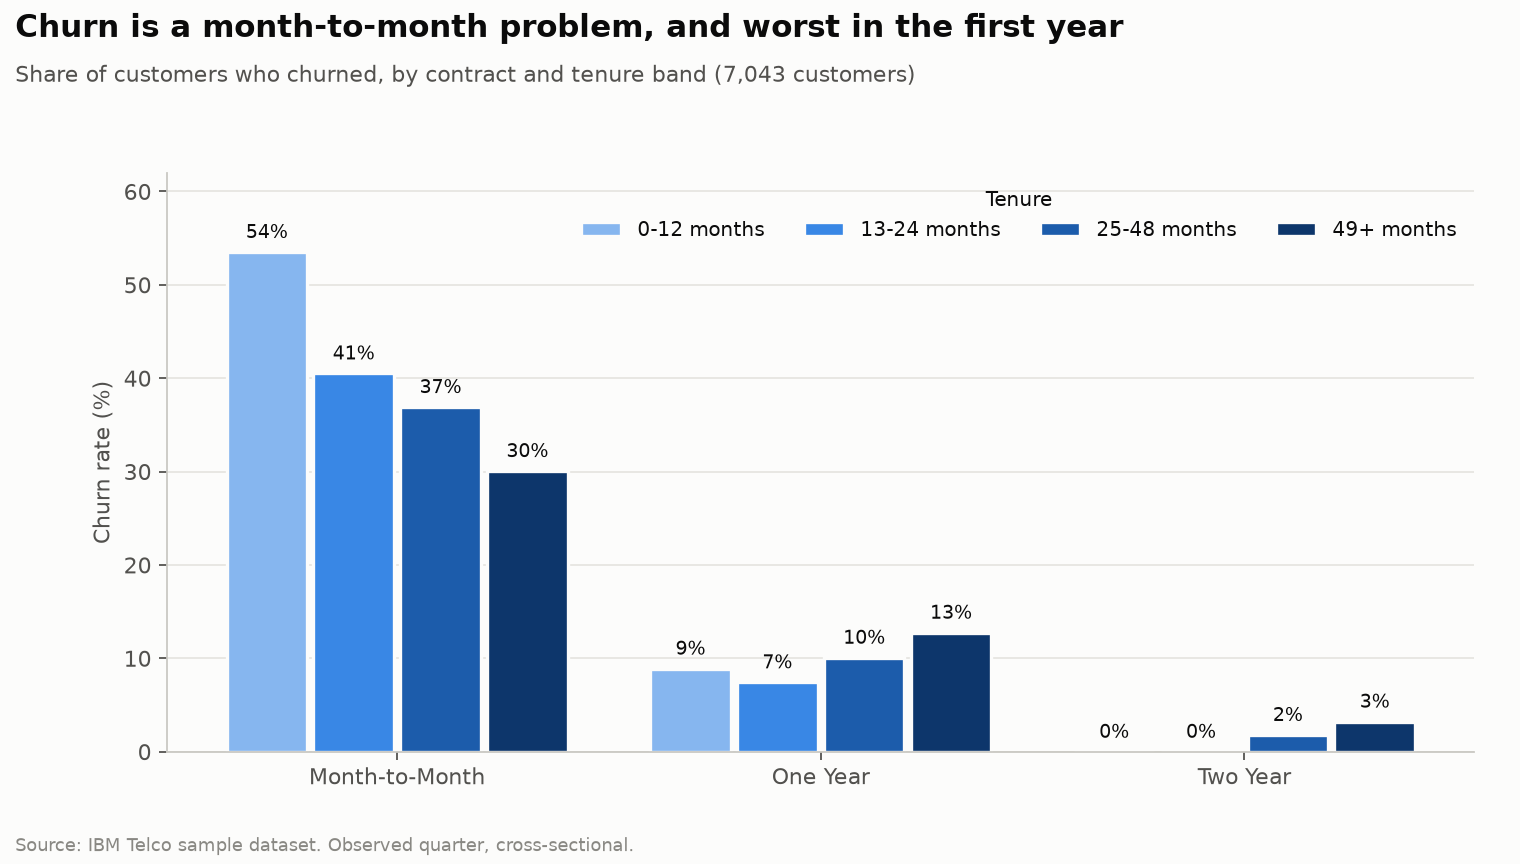

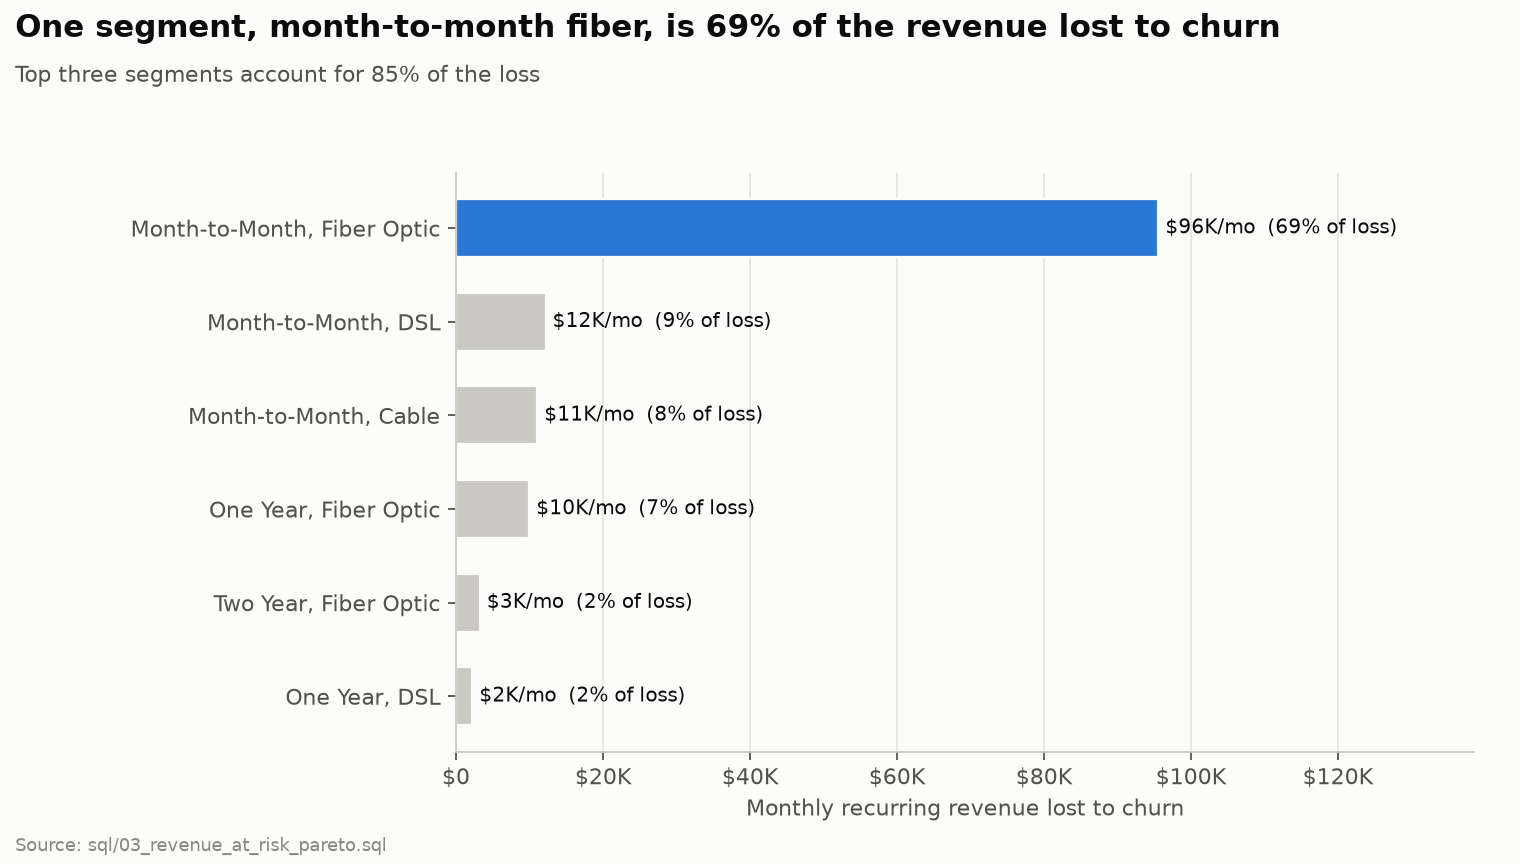

In [7]:
overview = sql["churn_overview"].iloc[0]
first_year = sql["churn_by_contract_and_tenure"].iloc[0]
top = sql["revenue_at_risk_pareto"].iloc[0]
third = sql["revenue_at_risk_pareto"].iloc[2]
display(Markdown(f"""
### What the queries say

- **{overview.churn_rate_pct:.1f}% of customers churned, but {overview.revenue_lost_pct:.1f}% of monthly revenue.** Churners pay {usd(overview.avg_charge_churners, 2)} a month against {usd(overview.avg_charge_stayers, 2)} for stayers, so the revenue problem is bigger than the headcount problem.
- **Month-to-month customers in their first year are {first_year.share_of_all_churners_pct:.0f}% of all churners** ({first_year.churn_rate_pct:.0f}% of them churn).
- **{top.contract} {top.internet_type} is {top.share_of_loss_pct:.0f}% of the revenue lost**; the top three segments reach {third.cumulative_share_pct:.0f}%.
"""))
display(Image("outputs/figures/01_churn_by_contract_tenure.png"))
display(Image("outputs/figures/02_revenue_pareto.png"))

## 4. The offer trap: why the obvious comparison is wrong

The raw churn rate by offer looks like a ranking of retention offers. It is not. Each offer goes almost entirely to **one tenure band**, so comparing offers mostly compares customer age:

In [8]:
bands = pd.cut(df.tenure_months, [0, 6, 12, 24, 48, 1000], labels=["0-6", "7-12", "13-24", "25-48", "49+"])
share = (pd.crosstab(df.offer, bands, normalize="index") * 100).round(0)
raw_rate = df.groupby("offer").churn.mean().mul(100).round(1).rename("raw churn %")
display(share.join(raw_rate).style.format("{:.0f}", subset=share.columns))

,0-6,7-12,13-24,25-48,49+,raw churn %
offer,,,,,,
None,22,10,14,25,29,27.100000
Offer A,0,0,0,0,100,6.700000
Offer B,0,0,0,29,71,12.300000
Offer C,0,0,8,92,0,22.900000
Offer D,0,27,73,0,0,26.700000
Offer E,79,21,0,0,0,52.900000


In [9]:
offers = sql["offer_confounding"]
display(offers[["offer", "tenure_band", "customers", "churn_pct", "no_offer_churn_pct", "gap_vs_no_offer_points"]])
e = offers[offers.offer == "Offer E"].iloc[0]
others = offers[offers.offer != "Offer E"]
better = others[others.gap_vs_no_offer_points < 0]
worse = others[others.gap_vs_no_offer_points >= 0]
exceptions = ", ".join(f"{r.offer} at {r.tenure_band[3:]} ({r.gap_vs_no_offer_points:+.1f} pts)" for r in worse.itertuples())
display(Markdown(f"""
Offer E looks terrible raw ({e.offer_raw_churn_pct:.0f}% churn) only because it is given to brand-new customers. Compared with **customers in the same tenure band who got no offer**, it is {e.gap_vs_no_offer_points:+.1f} points in the 0-6 month band, still worse than no offer. For offers A to D, churn is lower than the no-offer group in the same band in {len(better)} of {len(others)} comparisons (by {-better.gap_vs_no_offer_points.max():.0f} to {-better.gap_vs_no_offer_points.min():.0f} points); the exceptions are {exceptions}. Even this like-for-like view is observational (the bands are coarse and nobody randomized who got what), so it is a hypothesis for the experiment, not a verdict.
"""))

,offer,tenure_band,customers,churn_pct,no_offer_churn_pct,gap_vs_no_offer_points
0,Offer A,5: 49+ months,520,6.7,10.0,-3.3
1,Offer B,4: 25-48 months,243,15.2,20.7,-5.5
2,Offer B,5: 49+ months,581,11.0,10.0,1.0
3,Offer C,3: 13-24 months,35,22.9,31.4,-8.5
4,Offer C,4: 25-48 months,380,22.9,20.7,2.2
5,Offer D,2: 7-12 months,161,29.2,38.2,-9.0
6,Offer D,3: 13-24 months,441,25.9,31.4,-5.5
7,Offer E,1: 0-6 months,635,57.8,49.9,7.9
8,Offer E,2: 7-12 months,170,34.7,38.2,-3.5



Offer E looks terrible raw (53% churn) only because it is given to brand-new customers. Compared with **customers in the same tenure band who got no offer**, it is +7.9 points in the 0-6 month band, still worse than no offer. For offers A to D, churn is lower than the no-offer group in the same band in 5 of 7 comparisons (by 3 to 9 points); the exceptions are Offer B at 49+ months (+1.0 pts), Offer C at 25-48 months (+2.2 pts). Even this like-for-like view is observational (the bands are coarse and nobody randomized who got what), so it is a hypothesis for the experiment, not a verdict.


## 5. One more oddity: the referral count

`number_of_referrals` is the second-strongest feature in the model, so it deserves a look.

In [10]:
by_ref = df.groupby("number_of_referrals").agg(customers=("churn", "size"), churn_rate=("churn", "mean")).T
display(by_ref.round(3))
print("corr(referrals, tenure):", round(df.number_of_referrals.corr(df.tenure_months), 2))

number_of_referrals,0,1,2,3,4,5,6,7,8,9,10,11
customers,3821.000,1086.000,236.00,255.000,236.000,264.00,221.000,248.000,213.000,238.000,223.0,2.0
churn_rate,0.326,0.467,0.11,0.125,0.076,0.08,0.036,0.024,0.009,0.017,0.0,0.0


corr(referrals, tenure): 0.33


Churn is *higher* at one referral (47%) than at none (33%), then collapses at two or more. The count is a lifetime total, so it grows with tenure, and the shape is not monotonic. It carries real signal beyond tenure (dropping it costs about two AUC points), but it is a cumulative quantity measured up to the exit date, so it sits in the **strict** feature set alongside the billing totals. A reader who distrusts cumulative counts should use the strict numbers.

## 6. What a retention team should do with this

1. **Start with month-to-month fiber customers in their first year.** One segment holds most of the lost revenue.
2. **Test a contract-upgrade offer** for that segment. Contract type is the strongest driver in every view (odds ratios, SHAP, permutation importance).
3. **Test bundling tech support or online security** for month-to-month internet customers. Within the same plan and contract, customers with either churn 17 to 25 points less (`sql/04`). Association only.
4. **Do not use the current offers as evidence of what works.** They are assigned by tenure; only a randomized test can say.

## Limitations

- One quarter, one region, one company, and synthetic data: nothing here is a claim about real telco customers.
- No timestamps, so there is no forecasting horizon and no way to check drift over time.
- Cumulative columns carry a small look-ahead (see the strict feature set).
- All associations are observational.